# Transient pumping-test analysis in semi-confined aquifers – Hantush method

**Hydraulic Methods · Hydrogeology**

This notebook deals with pumping tests in a **leaky (semi-confined) aquifer** using the Hantush–Jacob solution. The numerical implementation of the well function draws in part on [T. N. Olsthoorn](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html).

**Learning objectives:**

1. Compare Theis and Hantush type curves.
2. Simulate a synthetic pumping test and estimate **T** and **S**.
3. Determine the best-fitting type curve when the leakage parameter **r/B** is unknown.
4. Apply the method to measurements from a course exercise.

**Requirements:** `numpy`, `scipy`, `matplotlib`. All calculations use SI units.

## 1. Theory

### What is a semi-confined aquifer?

A **semi-confined aquifer** (*leaky aquifer*) is overlain or underlain by a layer with **lower hydraulic conductivity** than the aquifer, but which is not completely impermeable (**aquitard**). Differences in hydraulic head allow vertical inflow or outflow (*leakage*) through the aquitard. During a pumping test, this additional supply can reduce drawdown compared with a fully confined aquifer.

As a **rule of thumb**, a semi-confined aquifer is sometimes described as having an aquitard with hydraulic conductivity approximately **two to four orders of magnitude lower** than that of the aquifer (roughly **K/K′ = 10² to 10⁴**; [Grundwasser.net: Semi-confined aquifer](https://www.grundwasser.net/pumpversuche/halbgespannter-aquifer-hantush), in German). This is **not a universal or sharply defined classification criterion**. The aquitard thickness, and therefore its hydraulic resistance, are also crucial to the hydraulic response.

### Theis solution (confined aquifer)

The time-dependent drawdown **s** at distance **r** from a pumping well operating at constant discharge **Q** is:

$$
s(u)=\frac{Q}{4\pi T}W(u),\qquad
u=\frac{r^2 S}{4Tt},\qquad W(u)=E_1(u)=\int_u^\infty\frac{e^{-x}}{x}\,\mathrm{d}x.
$$

### Hantush–Jacob solution (leaky aquifer)

When water leaks through a low-permeability confining layer, the well function additionally depends on the dimensionless ratio **r/B**:

$$
s(u)=\frac{Q}{4\pi T}\,W\!\left(u,\frac rB\right),
\qquad
W(u,\rho)=\int_u^\infty \frac{1}{x}\exp\!\left(-x-\frac{\rho^2}{4x}\right)\mathrm{d}x,
\quad \rho=\frac rB.
$$

The **leakage factor B** is defined as:

$$
B=\sqrt{T\,\frac{M'}{K'}}=\sqrt{Tc},\qquad c=\frac{M'}{K'}.
$$

| Symbol | Meaning | Units |
|:--|:--|:--|
| **Q** | Pumping rate | m³/s |
| **t**, **r**, **s** | Time, distance, drawdown | s, m, m |
| **T** | Transmissivity | m²/s |
| **K** | Hydraulic conductivity of the aquifer | m/s |
| **S** | Aquifer storativity | – |
| **M′**, **K′** | Thickness, hydraulic conductivity of the low-permeability layer | m, m/s |
| **c** | Hydraulic resistance of the low-permeability layer | s |
| **B** | Leakage factor (characteristic length) | m |
| **ρ = r/B** | Dimensionless leakage parameter | – |

For very small **r/B**, the Hantush solution approaches the Theis solution. At larger values, vertical leakage limits the increase in drawdown over time.

**Model assumptions:** constant pumping rate, horizontal radial flow in the aquifer, homogeneous properties, a fully penetrating well, constant hydraulic head above the low-permeability layer, and negligible storage in that layer. This simplified Hantush–Jacob solution does not apply to every leaky-aquifer system.

## 2. Functions and plotting settings

The Hantush well function is evaluated using numerical integration. For **r/B = 0**, the Theis well function is used directly. To estimate parameters, **T** and **S** are parametrized logarithmically so that they remain positive. The goodness of fit is reported as **RMSE**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import least_squares
from scipy.special import exp1

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

LANG = 'EN'
LABELS = {'time': 'Time since pumping started t [s]', 'drawdown': 'Drawdown s [m]', 'obs': 'Observations', 'fit': 'Hantush fit', 'true': 'Hantush model without measurement noise', 'theis': 'Theis', 'exclude': '', 'syn_observe': 'Synthetic pumping test – observations (linear)', 'syn_fit': 'Synthetic pumping test – known leakage parameter (log–log)', 'syn_grid': 'Synthetic pumping test – unknown leakage parameter (log–log)', 'real_observe': 'Exercise – observations (linear)', 'real_fit': 'Exercise – Hantush fit (log–log)', 'residuals': 'Residuals [m]', 'resid_title': 'Exercise – fit residuals', 'type_title': 'Theis and Hantush type curves', 'known': 'Known r/B', 'summary_grid': 'Parameter estimates for selected r/B values', 'summary_best': 'Best fit'}


def calc_u(t, T, S, r):
    """Dimensionless time parameter u."""
    return r**2 * S / (4 * T * np.asarray(t, dtype=float))


def calc_B(T, M_prime, K_prime):
    """Leakage factor B [m]."""
    return np.sqrt(T * M_prime / K_prime)


def calc_rho(r, B):
    """Dimensionless leakage parameter rho = r/B."""
    if B <= 0 or r <= 0:
        raise ValueError("r and B must be positive")
    return r / B


def hantush_well_function(u, rho):
    """Hantush–Jacob well function W(u, rho); positive scalar u and nonnegative rho."""
    if u <= 0 or rho < 0:
        raise ValueError("u must be positive and rho must be nonnegative")
    if rho == 0:
        return float(exp1(u))
    integrand = lambda x: np.exp(-x - rho**2 / (4 * x)) / x
    value, _ = quad(integrand, u, np.inf, epsabs=1e-11, epsrel=1e-9, limit=150)
    return value


def hantush_drawdown(t, T, S, Q, r, rho):
    """Drawdown [m], for times in seconds, using a fixed rho = r/B."""
    times = np.atleast_1d(np.asarray(t, dtype=float))
    if np.any(times <= 0) or min(T, S, Q, r) <= 0 or rho < 0:
        raise ValueError("t, T, S, Q and r must be positive; rho must be nonnegative")
    u = calc_u(times, T, S, r)
    result = np.array([hantush_well_function(float(ui), float(rho)) for ui in u])
    return Q / (4 * np.pi * T) * result


def rmse(observed, modelled):
    """Root mean square error in metres."""
    return np.sqrt(np.mean((np.asarray(observed) - np.asarray(modelled)) ** 2))


def fit_at_rho(t, s, Q, r, rho, start_T=1e-3, start_S=1e-3):
    """Least-squares fit of positive T and S for a given rho."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    if t.shape != s.shape or np.any(t <= 0) or np.any(s < 0):
        raise ValueError("t and s must have the same shape, with t>0 and s>=0")

    def residuals(log_params):
        T, S = np.exp(log_params)
        return hantush_drawdown(t, T, S, Q, r, rho) - s

    lower = np.log([1e-8, 1e-9])
    upper = np.log([1.0, 0.5])
    result = least_squares(residuals, np.log([start_T, start_S]),
                           bounds=(lower, upper), max_nfev=700,
                           ftol=1e-11, xtol=1e-11, gtol=1e-11)
    T_fit, S_fit = np.exp(result.x)
    prediction = hantush_drawdown(t, T_fit, S_fit, Q, r, rho)
    return {"rho": float(rho), "T": T_fit, "S": S_fit,
            "rmse": rmse(s, prediction), "prediction": prediction}


def scan_rho(t, s, Q, r, rho_values):
    """Fit T, S for every candidate rho and return sorted results."""
    fits = [fit_at_rho(t, s, Q, r, float(rho)) for rho in rho_values]
    return sorted(fits, key=lambda item: item["rmse"])


def display_fit_table(fits):
    print(f"{'r/B':>8} {'T [m²/s]':>13} {'S [-]':>13} {'RMSE [m]':>13}")
    print('-' * 53)
    for f in sorted(fits, key=lambda d: d['rho']):
        print(f"{f['rho']:>8.3f} {f['T']:>13.4e} {f['S']:>13.4e} {f['rmse']:>13.5f}")


def plot_fit(t, observed, fit, title):
    # Logarithmic scales on both axes, analogous to type curves.
    t_fine = np.geomspace(np.min(t), np.max(t), 240)
    curve = hantush_drawdown(t_fine, fit['T'], fit['S'], fit['Q'], fit['r'], fit['rho'])
    fig, ax = plt.subplots()
    ax.loglog(t, observed, 'o', markersize=6, label=LABELS['obs'])
    ax.loglog(t_fine, curve, '-', linewidth=2, label=LABELS['fit'])
    ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=title)
    ax.legend()
    fig.tight_layout()
    plt.show()


def include_inputs(fit, Q, r):
    """Return a copy with the fixed exercise inputs used by plot_fit."""
    return dict(fit, Q=Q, r=r)


## 3. Theis and Hantush type curves

The type curves show **W(u, r/B)** against **1/u**. **Both axes use logarithmic scales**. Small values of **r/B** produce curves close to the Theis solution; larger values lead to earlier flattening.

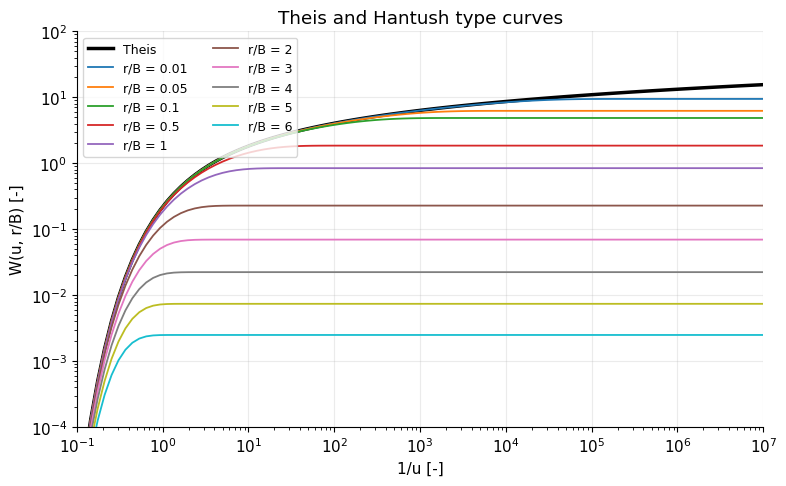

In [2]:
rho_type = np.array([0.01, 0.05, 0.1, 0.5, 1, 2, 3, 4, 5, 6], dtype=float)
u_type = np.logspace(-7, 1, 100)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(1/u_type, exp1(u_type), color="black", linewidth=2.5, label="Theis")
for rho in rho_type:
    w_h = np.array([hantush_well_function(float(u), float(rho)) for u in u_type])
    ax.loglog(1/u_type, w_h, linewidth=1.3, label=f"r/B = {rho:g}")
ax.set(xlabel="1/u [-]", ylabel="W(u, r/B) [-]", title=LABELS['type_title'],
       xlim=(1e-1, 1e7), ylim=(1e-4, 1e2))
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Synthetic pumping test

We generate measurements using known parameters and add a small amount of random measurement noise. A fixed **random seed** ensures that the same values are generated each time.

**Inputs:** **Q = 0.002 m³/s**, **r = 10 m**, **T = 0.001 m²/s**, **S = 0.001**, **M′ = 3 m**, **K′ = 10⁻⁵ m/s**.

In [3]:
# Inputs: synthetic test data
Q_syn = 0.002                 # m³/s
r_syn = 10.0                 # m
T_syn, S_syn = 1e-3, 1e-3   # m²/s, -
M_prime, K_prime = 3.0, 1e-5  # m, m/s

t_syn = np.array([120, 160, 200, 300, 400, 500, 600, 700, 800,
                  900, 1000, 1200, 1400, 1600, 1800, 2000, 2400, 2800], dtype=float)

B_syn = calc_B(T_syn, M_prime, K_prime)
rho_syn = calc_rho(r_syn, B_syn)
s_syn_exact = hantush_drawdown(t_syn, T_syn, S_syn, Q_syn, r_syn, rho_syn)

rng = np.random.default_rng(42)
noise_relative = 0.005
s_syn = s_syn_exact * (1 + noise_relative * rng.standard_normal(len(t_syn)))

print(f"B = {B_syn:.3f} m; r/B = {rho_syn:.4f}")
print(f"n = {len(t_syn)}")

B = 17.321 m; r/B = 0.5774
n = 18


### 4.1 First: observations on linear axes

First, plot drawdown against time to inspect the measurements: **both axes are linear**.

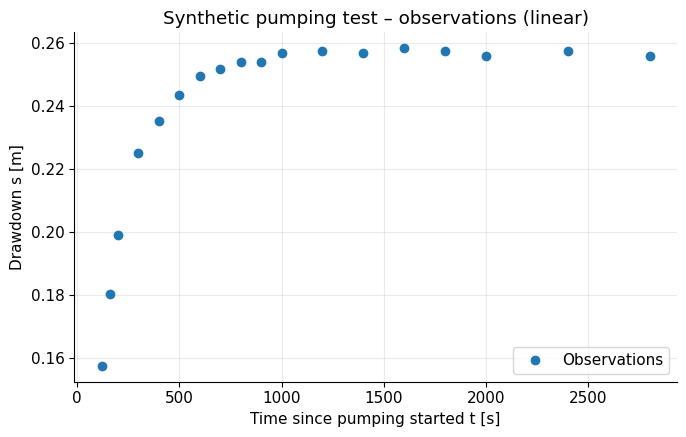

In [4]:
fig, ax = plt.subplots()
ax.plot(t_syn, s_syn, 'o', markersize=6, label=LABELS['obs'])
ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=LABELS['syn_observe'])
ax.legend()
fig.tight_layout()
plt.show()

### 4.2 Fitting with known **r/B**

In this first step, **r/B** is known from the input parameters. Thus, only **T** and **S** are estimated by nonlinear least squares. The plot showing observations and fitted model is **log–log**.

We report the actual **RMSE** (root mean square error), not the unnormalized Euclidean norm of the residual vector.

Known r/B = 0.5774
T = 1.0002e-03 m²/s
S = 1.0028e-03 [-]
RMSE = 0.00104 m


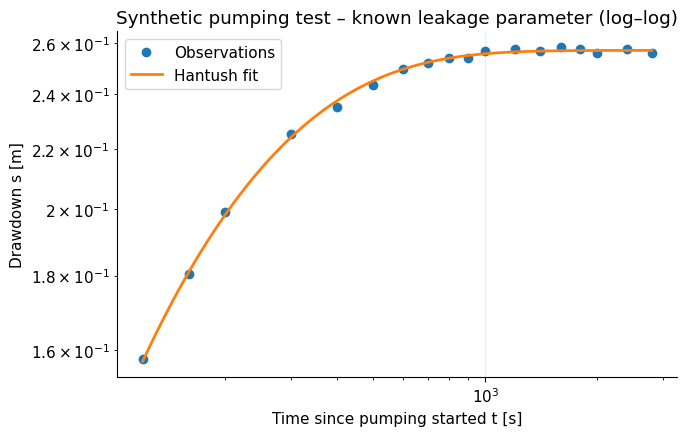

In [5]:
fit_known = fit_at_rho(t_syn, s_syn, Q_syn, r_syn, rho_syn)
print(LABELS['known'] + f" = {rho_syn:.4f}")
print(f"T = {fit_known['T']:.4e} m²/s")
print(f"S = {fit_known['S']:.4e} [-]")
print(f"RMSE = {fit_known['rmse']:.5f} m")
plot_fit(t_syn, s_syn, include_inputs(fit_known, Q_syn, r_syn), LABELS['syn_fit'])

### 4.3 Fitting with unknown **r/B**

For an actual pumping test, **r/B** is usually unknown. We therefore try several **candidate values of r/B**. For each value, we fit **T** and **S** separately and compare the RMSE.

**Important:** This is a *discrete parameter search*. The result is the best value **among the candidates tested**, not necessarily the exact optimum.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.010    5.2828e-03    2.5246e-05       0.01241
   0.050    3.6975e-03    1.3399e-04       0.00933
   0.100    2.9219e-03    2.7954e-04       0.00733
   0.500    1.1421e-03    9.5589e-04       0.00111
   1.000    5.2541e-04    1.0252e-03       0.00334
   2.000    1.4340e-04    6.1771e-04       0.00702
   3.000    4.3941e-05    2.9497e-04       0.00918
   4.000    1.4160e-05    1.2932e-04       0.01071
   5.000    4.6945e-06    5.4239e-05       0.01191
   6.000    1.5853e-06    2.2143e-05       0.01289

Best fit: r/B = 0.500, T = 1.1421e-03 m²/s, S = 9.5589e-04, RMSE = 0.00111 m


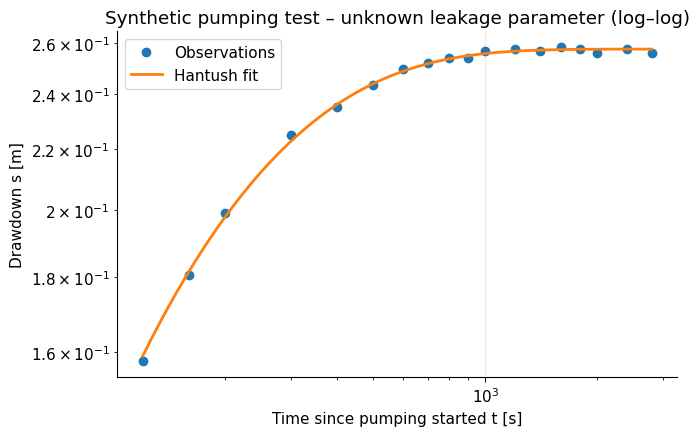

In [6]:
rho_coarse = np.array([0.01, 0.05, 0.1, 0.5, 1, 2, 3, 4, 5, 6])
fits_syn = scan_rho(t_syn, s_syn, Q_syn, r_syn, rho_coarse)
display_fit_table(fits_syn)
best_syn = fits_syn[0]
print("\n" + LABELS['summary_best'] + f": r/B = {best_syn['rho']:.3f}, "
      f"T = {best_syn['T']:.4e} m²/s, S = {best_syn['S']:.4e}, "
      f"RMSE = {best_syn['rmse']:.5f} m")
plot_fit(t_syn, s_syn, include_inputs(best_syn, Q_syn, r_syn), LABELS['syn_grid'])

**Interpretation:** The selected **r/B** should be close to the value used to generate the synthetic data. Deviations are expected because of measurement noise and a coarse candidate grid. More measurements, a finer search, or multiple observation wells can help constrain the estimates.

## 5. Exercise: pumping test in a leaky aquifer

We use the **18 measurements** from the exercise, with **Q = 6 L/s = 0.006 m³/s** and **r = 40 m**. Measured times are in **seconds** and drawdowns are in **metres**.

First, the observations are displayed on **linear axes**. We then search for **r/B**, first on a coarse grid and subsequently on a finer grid.

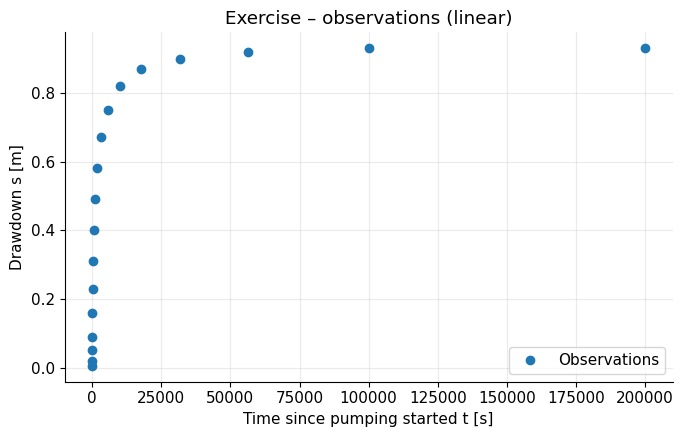

In [7]:
# Data from the exercise
Q_ex = 0.006
r_ex = 40.0

t_ex = np.array([10, 18, 32, 56, 100, 178, 316, 562, 1000,
                 1778, 3162, 5623, 10000, 17780, 31629, 56230, 100000, 200000], dtype=float)
s_ex = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31, 0.4, 0.49,
                 0.58, 0.67, 0.75, 0.82, 0.87, 0.9, 0.92, 0.93, 0.93], dtype=float)

assert len(t_ex) == len(s_ex) and np.all(np.diff(t_ex) > 0)

fig, ax = plt.subplots()
ax.plot(t_ex, s_ex, 'o', markersize=6, label=LABELS['obs'])
ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=LABELS['real_observe'])
ax.legend()
fig.tight_layout()
plt.show()

### 5.1 Coarse search

First, we use the candidate **r/B** values used above. We compare the fits using the **RMSE in metres**. The plot of the fitted curve and measurements uses **log–log axes**.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.010    4.0071e-03    1.0897e-04       0.05448
   0.050    3.1469e-03    1.7535e-04       0.01243
   0.100    2.5443e-03    2.4788e-04       0.01440
   0.500    1.0354e-03    4.2115e-04       0.07418
   1.000    4.8301e-04    3.7159e-04       0.09682
   2.000    1.3342e-04    1.9562e-04       0.11605
   3.000    4.1130e-05    8.8221e-05       0.12554
   4.000    1.3303e-05    3.7431e-05       0.13150
   5.000    4.4211e-06    1.5374e-05       0.13567
   6.000    1.4952e-06    6.1951e-06       0.13878

Best fit: r/B = 0.050, T = 3.1469e-03 m²/s, S = 1.7535e-04, RMSE = 0.01243 m


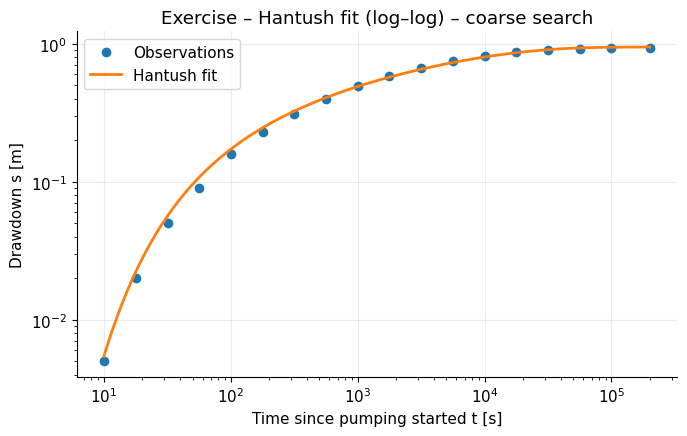

In [8]:
fits_ex_coarse = scan_rho(t_ex, s_ex, Q_ex, r_ex, rho_coarse)
display_fit_table(fits_ex_coarse)
best_ex_coarse = fits_ex_coarse[0]
print("\n" + LABELS['summary_best'] + f": r/B = {best_ex_coarse['rho']:.3f}, "
      f"T = {best_ex_coarse['T']:.4e} m²/s, S = {best_ex_coarse['S']:.4e}, "
      f"RMSE = {best_ex_coarse['rmse']:.5f} m")
plot_fit(t_ex, s_ex, include_inputs(best_ex_coarse, Q_ex, r_ex), LABELS['real_fit'] + (' – grobe Suche' if LANG == 'DE' else ' – coarse search'))

### 5.2 Refined search

We now refine the search grid for **r/B** to **0.04–0.10** (increments of 0.01). This makes it easy to examine how the candidate selection affects the outcome.

These are not independent measurements of leakage. **T**, **S**, and **r/B** are estimated solely from the same drawdown time series; possible parameter correlations and measurement errors must be considered.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.040    3.3239e-03    1.5733e-04       0.02001
   0.050    3.1469e-03    1.7535e-04       0.01243
   0.060    2.9952e-03    1.9208e-04       0.00647
   0.070    2.8627e-03    2.0759e-04       0.00381
   0.080    2.7452e-03    2.2199e-04       0.00662
   0.090    2.6398e-03    2.3539e-04       0.01058
   0.100    2.5443e-03    2.4788e-04       0.01440

Best fit:
r/B = 0.070 [-]
T = 2.8627e-03 m²/s
S = 2.0759e-04 [-]
RMSE = 0.00381 m
B = 571.4 m
c = 1.1407e+08 s


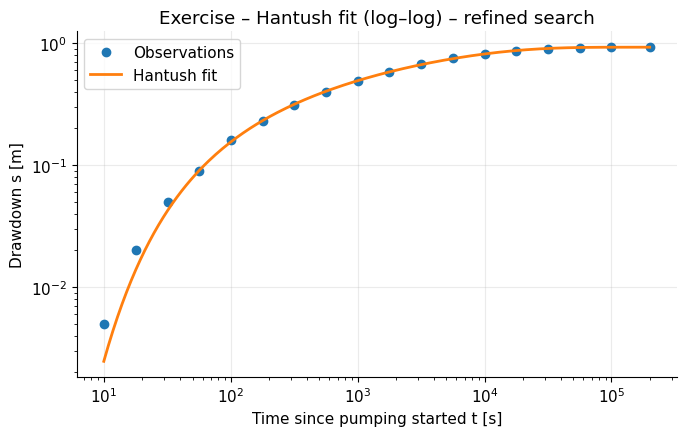

In [9]:
rho_fine = np.arange(0.04, 0.101, 0.01)
fits_ex_fine = scan_rho(t_ex, s_ex, Q_ex, r_ex, rho_fine)
display_fit_table(fits_ex_fine)
best_ex = fits_ex_fine[0]
B_ex = r_ex / best_ex['rho']
c_ex = B_ex**2 / best_ex['T']

print("\n" + LABELS['summary_best'] + ":")
print(f"r/B = {best_ex['rho']:.3f} [-]")
print(f"T = {best_ex['T']:.4e} m²/s")
print(f"S = {best_ex['S']:.4e} [-]")
print(f"RMSE = {best_ex['rmse']:.5f} m")
print(f"B = {B_ex:.1f} m")
print(f"c = {c_ex:.4e} s")
plot_fit(t_ex, s_ex, include_inputs(best_ex, Q_ex, r_ex), LABELS['real_fit'] + (' – verfeinerte Suche' if LANG == 'DE' else ' – refined search'))

### 5.3 Residuals and interpretation

An additional plot shows **residuals (observed minus modelled drawdown)** on linear axes, making systematic differences easier to identify. A low RMSE and a good curve fit **do not guarantee a unique hydrogeological interpretation**.

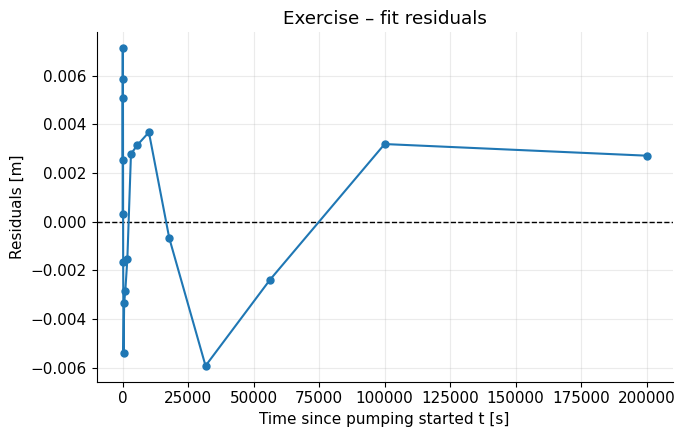

In [10]:
residuals_ex = s_ex - best_ex['prediction']
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.plot(t_ex, residuals_ex, 'o-', markersize=5)
ax.set(xlabel=LABELS['time'], ylabel=LABELS['residuals'], title=LABELS['resid_title'])
fig.tight_layout()
plt.show()

### 5.4 Which parameters have been identified?

Knowing **r**, the fitted **r/B** yields the leakage factor **B**. The fitted transmissivity **T** also provides the hydraulic resistance **c**:

$$
B=\frac{r}{r/B}, \qquad c=\frac{B^2}{T}, \qquad K'=\frac{M'}{c}.
$$

**K′** can be calculated **only if the layer thickness M′ is known independently**; the exercise does not provide this information. The pumping test alone therefore does not uniquely determine **K′** and **M′** separately.

**Note:** The estimates are conditional on the model assumptions. Late-time deviations may arise from boundaries, time-dependent leakage, or storage in the confining layer that is not represented here.

## 6. Summary and practical notes

- **Theis** is the limiting case without effective leakage; **Hantush–Jacob** incorporates vertical inflow through a low-permeability layer.
- **Type curves** and **Hantush fits** are shown on **log–log axes**; initial examination of the measurements uses **linear axes**.
- The search over **r/B** presented here is discrete. Additional candidate values can change the selected fit; RMSE alone does not quantify parameter uncertainty.
- To analyze your own measurements, replace **Q**, **r**, **t**, and **s** in Section 5. At early times, well losses and wellbore storage may violate the model assumptions.

### References and further reading

- Hantush, M. S. & Jacob, C. E. (1955): *Non-steady radial flow in an infinite leaky aquifer*. Transactions, American Geophysical Union, 36(1), 95–100. [DOI](https://doi.org/10.1029/TR036i001p00095).
- Olsthoorn, T. N.: [Well in a Leaky Aquifer – Transient Groundwater Flow](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html) (code source, online).
- [Grundwasser.net – Semi-confined aquifer (Hantush 1955)](https://www.grundwasser.net/pumpversuche/halbgespannter-aquifer-hantush) (in German; explains aquitards, leakage, and the approximate conductivity contrast).
- Langguth, H.-R. & Voigt, R. (1980): *Hydrogeologische Methoden*. Springer, Berlin, Heidelberg. [DOI](https://doi.org/10.1007/978-3-642-96581-4) (general reference; not a source for precise cutoff values).